# Lab: Build your first image encoder-decoder

**Time:** 60-90 minutes. **Prerequisites:** Python, tensors, basic convolutions, and gradient descent.

Read [CNN-Based Encoder-Decoder Architectures for Images](../../lectures/encoder_decoder/encoder_decoder.md), especially Sections 2-7.

You will reconstruct handwritten digits using a small convolutional network. Each image is both the input and the target: this training task makes our encoder-decoder an **autoencoder**. Digit labels are not used for training.

By the end, you should be able to:
- implement an encoder, spatial latent representation, and decoder;
- trace `[N, C, H, W]` shapes through downsampling and upsampling;
- train with reconstruction MSE and inspect held-out reconstructions;
- measure latent size and explain the bottleneck trade-off.

Complete the four TODO sections. Data loading, plotting, and evaluation are provided. TODO cells intentionally raise `NotImplementedError` until you implement them. Run cells in order.

## 1. Set up and load data (10 minutes)


In [1]:
# %pip install torch torchvision matplotlib

Device: cuda


100%|██████████| 9.91M/9.91M [00:00<00:00, 18.1MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 497kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.58MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 16.7MB/s]


Batch: (64, 1, 28, 28) Pixel range: 0.0 1.0


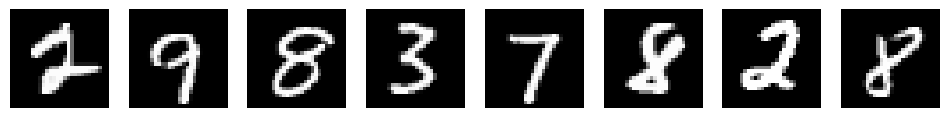

In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 64
EPOCHS = 5  # Start with 1 to check your code, then train for 5.
LATENT_CHANNELS = 8
print("Device:", device)

train_data = datasets.MNIST("./data", train=True, download=True, transform=transforms.ToTensor())
test_data = datasets.MNIST("./data", train=False, download=True, transform=transforms.ToTensor())
# Fixed random subsets keep the exercise small and comparisons repeatable.
g = torch.Generator().manual_seed(42)
train_data = Subset(train_data, torch.randperm(len(train_data), generator=g)[:5000].tolist())
test_data = Subset(test_data, torch.randperm(len(test_data), generator=g)[:1000].tolist())
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
images, labels = next(iter(train_loader))
print("Batch:", tuple(images.shape), "Pixel range:", images.min().item(), images.max().item())
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, img in zip(axes, images[:8]):
    ax.imshow(img[0], cmap="gray", vmin=0, vmax=1)
    ax.axis("off")
plt.show()

## 2. Predict the shapes (10 minutes)
Before coding, fill in the blanks. Use the convolution formulas in Sections 3.1 and 5.1 of the lecture. Assume dilation 1.

| Stage | Layer | Output shape |
|---|---|---|
| Input | — | `[N, 1, 28, 28]` |
| Encoder 1 | Conv2d: 1 → 16, kernel 3, stride 2, padding 1; ReLU | `[N, 16, 14, 14]` |
| Encoder 2 | Conv2d: 16 → 32, kernel 3, stride 2, padding 1; ReLU | `[N, 32, 7, 7]` |
| Bottleneck | Conv2d: 32 → L, kernel 1 | `[N, L, 7, 7]` |
| Decoder 1 | ConvTranspose2d: L → 16, kernel 3, stride 2, padding 1, output_padding 1; ReLU | `[N, 16, 14, 14]` |
| Decoder 2 | ConvTranspose2d: 16 → 1, same spatial settings; Sigmoid | `[N, 1, 28, 28]` |

**Write your answers here:**

*Working.* Encoder: $H_{out}=\lfloor (H+2p-k)/s\rfloor+1=\lfloor(28+2-3)/2\rfloor+1=14$, then $\lfloor(14+2-3)/2\rfloor+1=7$. The 1×1 bottleneck keeps $7\times7$. Decoder: $H_{out}=(H-1)s-2p+k+\text{output\_padding}$, so $(7-1)\cdot2-2+3+1=14$ and $(14-1)\cdot2-2+3+1=28$.

1. For `L=8`, input values per image = **784** (1×28×28); latent values = **392** (8×7×7); input/latent ratio = **2.0**.
2. For `L=32`, the latent has 32×7×7 = **1568** values, twice the 784 input values (ratio 0.5). So it is **not** dimensionally compressed: the spatial grid shrank 16× (28×28 → 7×7) but the channel count grew from 1 to 32, so the tensor actually holds more numbers than the input.
3. The Sigmoid squashes every output into (0, 1), which is exactly the pixel range produced by `ToTensor()`. The network therefore cannot predict impossible values, and the MSE target and output live on the same scale.
4. With `output_padding=0`: $(7-1)\cdot2-2+3+0=\mathbf{13}$. The decoder would give 13×13 (then 25×25), so the final image would not match the 28×28 input. `output_padding=1` is what resolves the stride-2 size ambiguity.

The 1×1 bottleneck mixes channels at each location. It preserves the spatial grid; no flattening or linear layer is needed. The input/latent ratio counts tensor values, not file size or actual encoded bits.

## 3. Implement the network (20 minutes)


In [3]:
class Encoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        # TODO 1: define self.network.
        self.network = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),   # [N, 16, 14, 14]
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),  # [N, 32, 7, 7]
            nn.ReLU(),
            nn.Conv2d(32, latent_channels, kernel_size=1),          # [N, L, 7, 7] (no activation)
        )

    def forward(self, x):
        return self.network(x)

In [4]:
class Decoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        # TODO 2: define self.network.
        self.network = nn.Sequential(
            nn.ConvTranspose2d(latent_channels, 16, kernel_size=3, stride=2, padding=1, output_padding=1),  # [N, 16, 14, 14]
            nn.ReLU(),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),                # [N, 1, 28, 28]
            nn.Sigmoid(),
        )

    def forward(self, z):
        return self.network(z)

In [5]:
class ImageEncoderDecoder(nn.Module):
    def __init__(self, latent_channels=8):
        super().__init__()
        self.encoder = Encoder(latent_channels)
        self.decoder = Decoder(latent_channels)

    def forward(self, x):
        # TODO 3: encode, decode, and return both outputs.
        z = self.encoder(x)
        reconstruction = self.decoder(z)
        return reconstruction, z

In [6]:
# Shape and range checks: run these before training.
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
x = torch.rand(4, 1, 28, 28, device=device)
with torch.no_grad():
    reconstruction, z = model(x)
assert z.shape == (4, LATENT_CHANNELS, 7, 7), "Check encoder stride/padding/channels"
assert reconstruction.shape == x.shape, "Check decoder output_padding"
assert torch.isfinite(reconstruction).all(), "Output contains nonfinite values"
assert ((reconstruction >= 0) & (reconstruction <= 1)).all(), "Check output activation"
print("Input:", tuple(x.shape), "Latent:", tuple(z.shape), "Output:", tuple(reconstruction.shape))
print("Shape and range checks passed")

Input: (4, 1, 28, 28) Latent: (4, 8, 7, 7) Output: (4, 1, 28, 28)
Shape and range checks passed


## 4. Train to reconstruct (15 minutes)


In [7]:
def train_step(model, images, optimizer, criterion):
    # TODO 4: implement a reconstruction training step.
    optimizer.zero_grad()                          # clear old gradients
    reconstruction, _ = model(images)              # forward pass
    loss = criterion(reconstruction, images)       # target is the input image itself
    loss.backward()                                # backpropagate
    optimizer.step()                               # update encoder + decoder weights
    return loss.item()

Untrained held-out MSE: 0.18629
Epoch 1: train MSE=0.11827, held-out MSE=0.04370
Epoch 2: train MSE=0.03428, held-out MSE=0.02552
Epoch 3: train MSE=0.01680, held-out MSE=0.00982
Epoch 4: train MSE=0.00826, held-out MSE=0.00613
Epoch 5: train MSE=0.00558, held-out MSE=0.00449


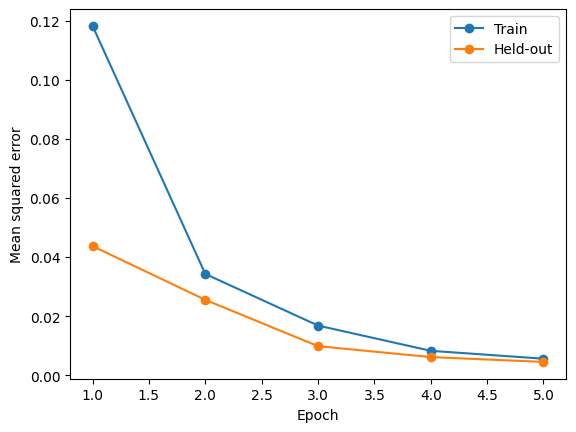

In [8]:
criterion = nn.MSELoss()

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstruction, _ = model(images)
        total_loss += criterion(reconstruction, images).item() * images.size(0)
    return total_loss / len(loader.dataset)

# Re-running this cell starts a fresh model and optimizer.
torch.manual_seed(42)
model = ImageEncoderDecoder(LATENT_CHANNELS).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
initial_mse = evaluate(model, test_loader)
print(f"Untrained held-out MSE: {initial_mse:.5f}")
history = {"train": [], "test": []}
for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        total_loss += train_step(model, images, optimizer, criterion) * images.size(0)
    history["train"].append(total_loss / len(train_loader.dataset))
    history["test"].append(evaluate(model, test_loader))
    print(f"Epoch {epoch + 1}: train MSE={history['train'][-1]:.5f}, "
          f"held-out MSE={history['test'][-1]:.5f}")

plt.plot(range(1, EPOCHS + 1), history["train"], marker="o", label="Train")
plt.plot(range(1, EPOCHS + 1), history["test"], marker="o", label="Held-out")
plt.xlabel("Epoch")
plt.ylabel("Mean squared error")
plt.legend()
plt.show()

## 5. Inspect the reconstruction and latent (10 minutes)
Look for digit identity, stroke thickness, and missing detail. A low average pixel error alone does not guarantee sharp or useful images. Feature maps are learned activations, not necessarily human-readable parts of a digit.

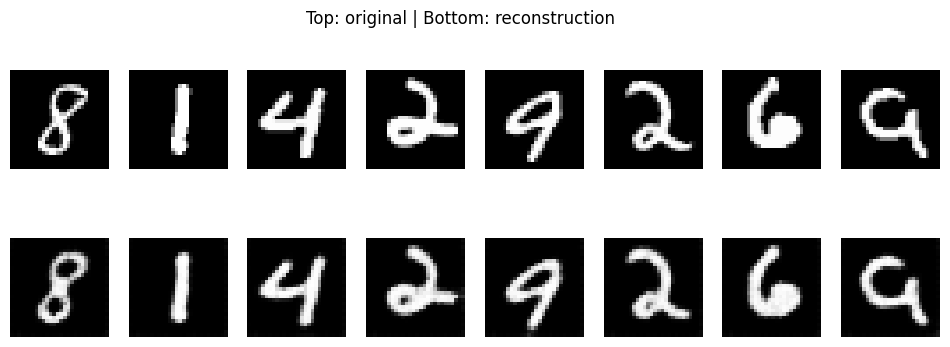

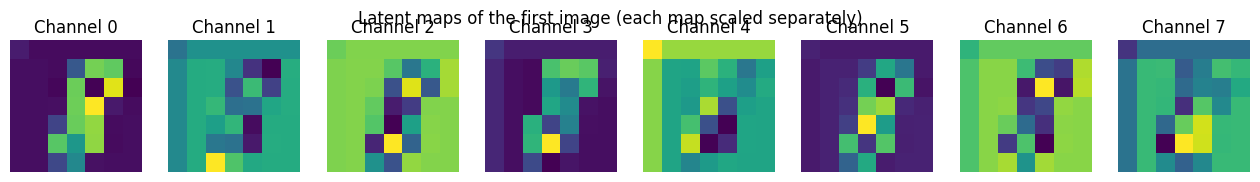

In [9]:
model.eval()
examples, _ = next(iter(test_loader))
with torch.no_grad():
    reconstructed, latents = model(examples[:8].to(device))
reconstructed, latents = reconstructed.cpu(), latents.cpu()
fig, axes = plt.subplots(2, 8, figsize=(12, 4))
for i in range(8):
    axes[0, i].imshow(examples[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[1, i].imshow(reconstructed[i, 0], cmap="gray", vmin=0, vmax=1)
    axes[0, i].axis("off")
    axes[1, i].axis("off")
fig.suptitle("Top: original | Bottom: reconstruction")
plt.show()

count = min(LATENT_CHANNELS, 8)
fig, axes = plt.subplots(1, count, figsize=(2 * count, 2), squeeze=False)
for i in range(count):
    axes[0, i].imshow(latents[0, i], cmap="viridis")
    axes[0, i].set_title(f"Channel {i}")
    axes[0, i].axis("off")
fig.suptitle("Latent maps of the first image (each map scaled separately)")
plt.show()

## 6. Experiment with the bottleneck (10-15 minutes)



  L  latent values  ratio  train MSE  held-out MSE  params
  2             98   8.00    0.01217       0.01072    5315
  8            392   2.00    0.00571       0.00467    6377
 32           1568   0.50    0.00371       0.00316   10625


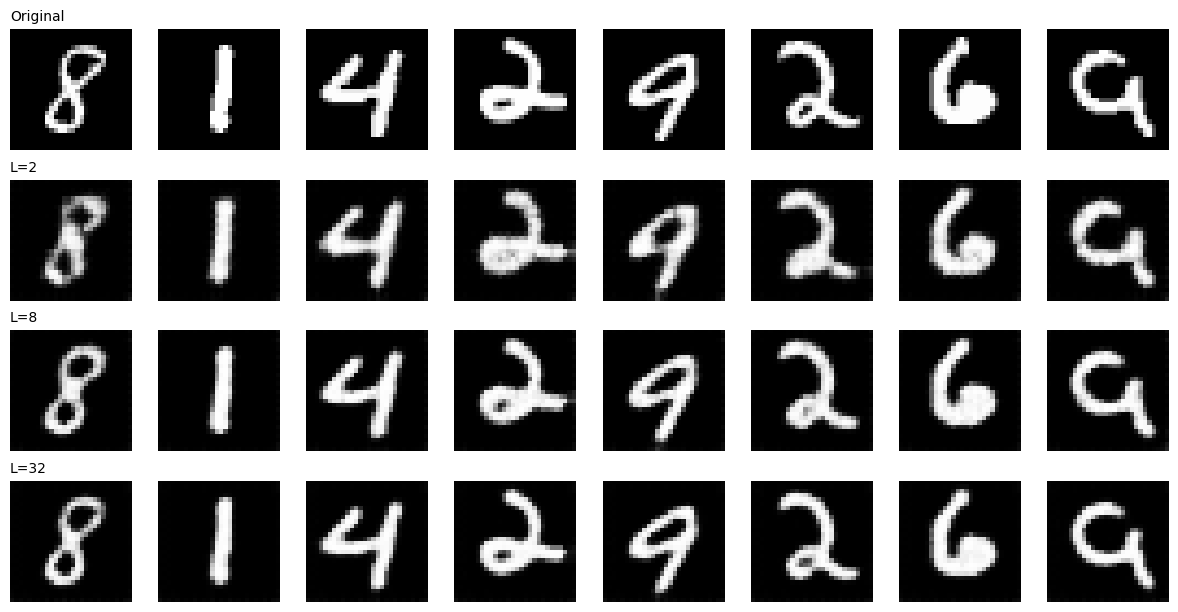

In [10]:
# Reproduces the three-run comparison. Same seed, data, learning rate and epoch count for each run.
def run_experiment(latent_channels):
    torch.manual_seed(42)
    m = ImageEncoderDecoder(latent_channels).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    for _ in range(EPOCHS):
        m.train()
        tot = 0.0
        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            tot += train_step(m, imgs, opt, criterion) * imgs.size(0)
    return m, tot / len(train_loader.dataset), evaluate(m, test_loader)

ex_images, _ = next(iter(test_loader))
ex_images = ex_images[:8]
rows, recons = [], {}
for L in (2, 8, 32):
    m, tr, te = run_experiment(L)
    m.eval()
    with torch.no_grad():
        recons[L] = m(ex_images.to(device))[0].cpu()
    vals = L * 7 * 7
    rows.append((L, vals, 784 / vals, tr, te, sum(p.numel() for p in m.parameters())))

print(f"{'L':>3} {'latent values':>14} {'ratio':>6} {'train MSE':>10} {'held-out MSE':>13} {'params':>7}")
for L, vals, ratio, tr, te, npar in rows:
    print(f"{L:>3} {vals:>14} {ratio:>6.2f} {tr:>10.5f} {te:>13.5f} {npar:>7}")

fig, axes = plt.subplots(4, 8, figsize=(12, 6.2))
labels_ = ["Original", "L=2", "L=8", "L=32"]
for r, (name, imgs_) in enumerate(zip(labels_, [ex_images] + [recons[L] for L in (2, 8, 32)])):
    for c in range(8):
        axes[r, c].imshow(imgs_[c, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, c].axis("off")
    axes[r, 0].set_title(name, loc="left", fontsize=10)
plt.tight_layout()
plt.show()

**Results** (5 epochs, seed 42, Adam lr 1e-3, CPU run copied from the experiment cell above; the last digit can shift slightly between runs, so the same cell may print marginally different values):

| Latent channels | Values per image | Input/latent ratio | Final train MSE | Final held-out MSE | Visible differences |
|---|---|---|---|---|---|
| 2 | 98 | 8.0 | 0.01217 | 0.01072 | Blurriest. Strokes are thickened and smeared; the loops of the 8 and the 2 fill in as blobs, though digit identity is still readable. |
| 8 | 392 | 2.0 | 0.00571 | 0.00467 | Clearly recognizable. Loops in the 8, 2 and 6 mostly survive; edges are slightly soft and thin gaps close up. |
| 32 | 1568 | 0.5 | 0.00371 | 0.00316 | Sharpest. Open loops and thin strokes are kept best; a little residual softness remains on the edges. |

Parameter counts: 5,315 (L=2), 6,377 (L=8), 10,625 (L=32). "Final train MSE" is the average over the last epoch's mini-batches while the weights were still changing, which is why it can sit above the held-out MSE.

**Discussion**

1. **Yes, in these runs.** Held-out MSE fell from 0.0107 (L=2) to 0.0047 (L=8) to 0.0032 (L=32), and the image grid agrees: L=2 smears the loops of the 8 and 2, L=8 is clearly recognizable, and L=32 is sharpest. The gains shrink, though: 2→8 cut the error by about 56%, while 8→32 cut it by about 32%. Caveats: this is one seed, the parameter count also rose (5.3k → 6.4k → 10.6k), and the held-out subset has been inspected repeatedly, so it is validation data.
2. **Downsampling only shrinks the grid, not the total number of values.** The grid goes from 28×28 to 7×7 (16× fewer positions), but the channel count rises from 1 to L. Compression depends on the total value count L·7·7 against 784: it is 2× for L=8, but at L=32 the latent has 1568 values and is *larger* than the input.
3. **The decoder estimates the image; it does not recover it.** Learned transposed convolutions can upsample the grid back to 28×28 and fill in typical digit-like strokes learned from the training data. But anything the encoder did not keep (exact edge positions, thin gaps, fine curvature) is gone, so the output is a plausible, usually smoother version of the input.
4. **A `[N, 128]` vector has no spatial layout.** It is 128 values (about 6× fewer than 784, stronger compression than L=8's 392), each unit can depend on the whole image, and the decoder needs a linear layer and a reshape to get back to a grid. The spatial latent keeps a 7×7 map where each position describes its own neighborhood, which preserves locality, uses far fewer parameters in the bottleneck, and stays fully convolutional.
5. **Skip connections:** the 14×14 feature maps after Encoder 1 (or the 7×7 maps after Encoder 2) could be concatenated or added to the matching decoder stage, as in a U-Net. That lets edges and fine detail travel around the bottleneck, which improves sharpness, but it weakens the constraint: the latent no longer has to carry all the information, and the network can drift toward copying the input, so latent size stops measuring how much was compressed.
6. **The model is only trained to reproduce inputs it has seen.** Nothing forces the latent space to follow a distribution we can sample from, and the decoder never saw arbitrary latent values. A random `z` will usually land in a region it was not trained on and produce garbage rather than a digit. Reliable generation needs something that defines the latent distribution, such as a VAE, GAN or diffusion model.


## Optional extension: denoising
Keep the architecture and start with a fresh model and optimizer. Add noise to the training **input**, while retaining the clean image as the **target**:

```python
noisy = (images + 0.3 * torch.randn_like(images)).clamp(0, 1)
reconstruction, _ = model(noisy)
loss = criterion(reconstruction, images)
```

Update both training and evaluation to use noisy inputs and clean targets. For evaluation, generate one fixed set of noisy held-out images and reuse it. Compare noisy-input MSE with denoised-output MSE against the clean images, and plot clean/noisy/reconstructed rows. Merely feeding noise to a reconstruction-trained model is not the same as training a denoiser.

An alternative extension is to replace each transposed convolution with 2× bilinear upsampling (`align_corners=False`) followed by a 3×3 convolution with padding 1. Keep the intermediate ReLU and final Sigmoid and check shapes before retraining.

## Submission and assessment
Submit the completed notebook with:
- all four TODOs implemented and shape checks passing (**4 marks**);
- your completed shape table and latent-size calculations (**2 marks**);
- training curves and original/reconstructed images (**2 marks**);
- the three-run experiment table and evidence-based discussion (**2 marks**).

Expected behavior: reconstruction error should generally decrease and reconstructed digits should become recognizable, though some strokes may remain blurred. No fixed MSE threshold is required. If training fails, check the target, output range, gradient update, and tensor shapes before increasing epochs.